# Photometrie einer Galaxie

Das Notebook holt die hellsten Galaxien des Himmels aus SIMBAD, bestimmt für eine ausgewählte Galaxie (voreingestellt M 51) Entfernung, Durchmesser und absolute Helligkeit aus den veröffentlichten Entfernungsmessungen und lädt Bilder in sechs Wellenlängenbereichen von NASA SkyView. Dem radialen Helligkeitsprofil bei 3.4 µm werden ein Sérsic-Profil und ein Modell aus Bulge und exponentieller Scheibe angepasst, eine NUV−W1-Farbkarte zeigt, wo junge Sterne sitzen, und die Ergebnisse werden mit der Zerlegung des Spitzer-Survey S4G verglichen.

Wie viel über den Aufbau einer Galaxie lässt sich allein aus der Verteilung ihres Lichts ablesen?

#### **Hintergrund**

Galaxien bestehen aus wenigen Bausteinen. Spiralgalaxien haben eine flache, rotierende **Scheibe** mit Gas, Staub und jungen Sternen, in der die Spiralarme liegen, und in der Mitte einen **Bulge**, eine runde oder leicht abgeplattete Verdickung aus überwiegend alten Sternen. Elliptische Galaxien sind fast reine Sphäroide ohne Scheibe. Das Hubble-Schema ordnet Galaxien nach diesem Verhältnis: Von elliptischen (E) über Linsengalaxien (S0) zu Spiralen von Sa (großer Bulge, eng gewundene Arme) bis Sd (kaum Bulge, offene Arme) und zu irregulären Galaxien.

Welche Bausteine man sieht, hängt von der Wellenlänge ab:
- **Ultraviolett** (GALEX, 0.23 µm): junge, massereiche Sterne, die nur einige zehn Millionen Jahre alt werden, also die Orte aktueller Sternentstehung.
- **Optisch** (DSS2, 0.47 und 0.65 µm): das Licht aller Sterne, durchzogen von Staubbändern, die blaues Licht stärker schlucken als rotes.
- **Nahes Infrarot** (2MASS K, 2.2 µm; WISE 3.4 µm): alte Sterne, die den größten Teil der Sternmasse ausmachen. Staub ist hier fast durchsichtig, deshalb verfolgt dieses Licht die Massenverteilung.
- **Mittleres Infrarot** (WISE 12 µm): warmer Staub und große Moleküle (PAH), die von jungen Sternen geheizt werden.

Um aus Winkeln physikalische Größen zu machen, braucht man die Entfernung. Für nahe Galaxien kommt sie aus der **Entfernungsleiter**: Cepheiden, die Spitze des Roten-Riesen-Asts (TRGB), die Leuchtkraftfunktion planetarischer Nebel (PNLF), Oberflächenhelligkeits-Fluktuationen oder die Tully-Fisher-Beziehung. Die Rotverschiebung hilft unter etwa 20 Mpc wenig, weil die Eigenbewegungen der Galaxien (einige hundert km/s) dort vergleichbar mit der Expansion sind.

Voreingestellt ist **M 51**, die Whirlpool-Galaxie, eine Spirale vom Typ Sbc fast von oben gesehen. Am Ende ihres nördlichen Arms hängt die kleinere Begleitgalaxie NGC 5195; die Wechselwirkung der beiden hat die ausgeprägten Spiralarme angeregt.

#### **Herleitung**

**1. Winkel und Länge.** Eine Strecke $s$ in der Entfernung $D$ erscheint unter dem kleinen Winkel $\theta = s/D$ (im Bogenmaß). Eine Bogenminute ist $\pi/(180 \cdot 60) = 2.909 \cdot 10^{-4}$ rad, also entspricht sie
$$s = 2.909 \cdot 10^{-4}\,D = 0.2909\,\text{kpc} \cdot \frac{D}{\text{Mpc}} .$$
Bei 7.5 Mpc sind das 2.2 kpc pro Bogenminute.

**2. Entfernungsmodul.** Der Strahlungsfluss fällt mit dem Quadrat der Entfernung, $F = L/(4\pi D^2)$. Die scheinbare Helligkeit ist $m = -2.5 \log_{10} F + \text{const}$, die absolute Helligkeit $M$ ist die scheinbare Helligkeit in 10 pc Entfernung. Die Differenz hängt nur vom Flussverhältnis ab:
$$m - M = -2.5 \log_{10}\frac{F(D)}{F(10\,\text{pc})} = -2.5 \log_{10}\left(\frac{10\,\text{pc}}{D}\right)^2 = 5 \log_{10}\frac{D}{10\,\text{pc}} .$$

**3. Hubble-Gesetz und Eigenbewegung.** Die gemessene Fluchtgeschwindigkeit setzt sich aus der Expansion und der Eigenbewegung (Pekuliargeschwindigkeit) zusammen,
$$v = H_0 D + v_\text{pec} .$$
Aus einer unabhängigen Entfernung folgt $v_\text{pec} = v - H_0 D$. Bei $v_\text{pec} \approx 300$ km/s und $H_0 = 70$ km/s/Mpc ist die Entfernung aus $v/H_0$ allein um etwa 4 Mpc unsicher, bei 8 Mpc also um 50 %.

**4. Elliptischer Radius und Neigung.** Ein Kreis vom Radius $r$ in einer dünnen Scheibe, die um den Winkel $i$ gegen die Sichtlinie geneigt ist, erscheint als Ellipse mit der großen Halbachse $r$ und der kleinen Halbachse $r\cos i$. Das Achsenverhältnis ist also $q = b/a = \cos i$. Der Positionswinkel PA der großen Achse wird von Norden über Osten gezählt. Mit den Bildkoordinaten $x$ (nach Osten) und $y$ (nach Norden) ist der Abstand entlang der großen Achse $x_a = x \sin \text{PA} + y \cos \text{PA}$ und entlang der kleinen Achse $x_b = x \cos \text{PA} - y \sin \text{PA}$. Der Radius in der Scheibenebene ist
$$r = \sqrt{x_a^2 + (x_b/q)^2} .$$
Pixel mit gleichem $r$ liegen auf derselben Ellipse; über sie wird gemittelt.

**5. Das Sérsic-Profil.** Sérsic (1963) beschrieb die Flächenhelligkeit mit
$$I(r) = I_e \exp\left\{-b_n\left[\left(\frac{r}{r_e}\right)^{1/n} - 1\right]\right\} .$$
$n = 1$ ist eine exponentielle Scheibe, $n = 4$ das de-Vaucouleurs-Profil elliptischer Galaxien. Die Konstante $b_n$ wird so gewählt, dass $r_e$ die Hälfte des Gesamtlichts einschließt. Das Licht innerhalb von $r$ auf Ellipsen mit dem Achsenverhältnis $q$ ist
$$L(<r) = 2\pi q \int_0^r I(r')\,r'\,dr' .$$
Mit der Substitution $x = b_n (r'/r_e)^{1/n}$, also $r' = r_e (x/b_n)^n$ und $dr' = r_e\,n\,x^{n-1}/b_n^n\,dx$, wird $r'\,dr' = r_e^2\,n\,x^{2n-1}/b_n^{2n}\,dx$ und
$$L(<r) = 2\pi q\,n\,I_e\,r_e^2\,\frac{e^{b_n}}{b_n^{2n}} \int_0^{x(r)} x^{2n-1} e^{-x}\,dx = 2\pi q\,n\,I_e\,r_e^2\,\frac{e^{b_n}}{b_n^{2n}}\,\gamma\big(2n, x(r)\big),$$
mit der unvollständigen Gammafunktion $\gamma$. Für $r \to \infty$ wird daraus $\Gamma(2n)$, das Gesamtlicht ist
$$L = 2\pi q\,n\,I_e\,r_e^2\,\frac{e^{b_n}\,\Gamma(2n)}{b_n^{2n}} .$$
Bei $r = r_e$ ist $x = b_n$. Die Bedingung „halbes Licht“ heißt also $\gamma(2n, b_n) = \Gamma(2n)/2$: $b_n$ ist der Median der Gammaverteilung mit Formparameter $2n$. Numerisch ist das `gammaincinv(2n, 0.5)`, näherungsweise $b_n \approx 2n - 1/3 + 0.0099/n$, also $b_1 = 1.678$ und $b_4 = 7.669$.

**6. Die exponentielle Scheibe.** Für $n = 1$ ist $I(r) = I_e e^{b_1} e^{-b_1 r/r_e} = I_0\,e^{-r/h}$ mit der zentralen Helligkeit $I_0 = I_e e^{b_1}$ und der Skalenlänge $h = r_e/b_1 = r_e/1.678$. Das Gesamtlicht aus Punkt 5 wird mit $\Gamma(2) = 1$ zu
$$L_\text{Scheibe} = 2\pi q\,I_0\,h^2 .$$
Die Milchstraße hat bei 3.6 µm eine Skalenlänge von etwa 2.6 kpc.

**7. Bulge und Scheibe.** Die Summe $I(r) = I_\text{Sérsic}(r) + I_0 e^{-r/h}$ beschreibt eine Spirale besser als ein einzelnes Sérsic-Profil. Mit den Gesamtlichtern aus Punkt 5 und 6 ist das Bulge-zu-Gesamt-Verhältnis
$$B/T = \frac{L_\text{Bulge}}{L_\text{Bulge} + L_\text{Scheibe}} .$$
Es fällt entlang der Hubble-Sequenz von etwa 0.4 bei Sa auf unter 0.1 bei Sc und später.

**8. Farbe.** Die Differenz zweier Helligkeiten ist ein Flussverhältnis, $m_1 - m_2 = -2.5 \log_{10}(F_1/F_2) + \text{const}$. NUV − W1 vergleicht das Licht junger Sterne mit der Sternmasse; ein kleinerer (blauerer) Wert heißt mehr Sternentstehung pro Masse. Ohne Kalibrierung der Bilder bleibt die Konstante offen; die Farbe ist dann nur relativ, aber Unterschiede innerhalb der Galaxie sind trotzdem messbar.

#### **Daten**

- **SIMBAD** (CDS Straßburg), abgefragt mit ADQL über TAP: Typ, Hubble-Klasse, Koordinaten, Helligkeiten, Größe aus der Tabelle `basic` und alle veröffentlichten Entfernungen aus `mesDistance`.
- **NED** (NASA/IPAC Extragalactic Database): die Fluchtgeschwindigkeit.
- **NASA SkyView**: Bilder aus sechs Durchmusterungen auf demselben Raster (400 × 400 Pixel); GALEX Near UV, DSS2 Blue und Red, 2MASS K, WISE 3.4 µm und 12 µm. Die Bilder sind umgerechnet und hier nicht flusskalibriert.
- **CDS hips2fits**: ein Farbbild aus dem Digitized Sky Survey.
- **S4G** (Spitzer Survey of Stellar Structure in Galaxies) über VizieR: die Zerlegung von Salo et al. (2015) bei 3.6 µm, für den Vergleich am Ende.

Downloads landen im astropy-Cache in `astrodata`. Der Download der Bilder dauert 20 bis 60 Sekunden; SkyView ist manchmal langsam. Bei sehr großen Galaxien (M 31, LMC, SMC) umfasst das Feld mehrere Grad; die SkyView-Mosaike von 2MASS und DSS2 zeigen dann Streifen und Plattenränder, WISE und GALEX bleiben sauber.

In [1]:
# In Colab fehlt astroquery; lokal ist es meist schon installiert
import importlib.util, subprocess, sys
if importlib.util.find_spec("astroquery") is None:
    if "google.colab" not in sys.modules:       # lokal nichts automatisch installieren: pip würde numpy mit aktualisieren
        raise ImportError("Es fehlt astroquery; bitte lokal selbst installieren, am besten mit conda (conda-forge), "
                          "damit numpy und die übrigen Pakete unverändert bleiben")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "astroquery"], check=True)

In [2]:
import os
from pathlib import Path

# Downloads landen im Ordner "astrodata" neben dem Notebook statt in den Caches im Home-Verzeichnis.
# Das muss vor dem ersten Import von astropy passieren; sonst den Kernel neu starten.
ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.optimize import curve_fit
from scipy.special import gammaincinv, gamma as gamma_fn
from scipy.ndimage import gaussian_filter
from astropy import units as u
from astropy.coordinates import SkyCoord, Angle
from astroquery.simbad import Simbad
from astroquery.ipac.ned import Ned
from astroquery.skyview import SkyView
from astroquery.hips2fits import hips2fits
from astroquery.vizier import Vizier

SELECTED_GALAXY = "M 51"   # Name wie in der Tabelle unten, z. B. "M 81", "M 101", "M 104", "M 87"
H0 = 70.0                  # Hubble-Konstante [km/s/Mpc]
pd.set_option("display.width", 160)

##### *1. Die hellsten Galaxien am Himmel*

Welche Galaxien sind hell und groß genug, um sie mit Bildern aus Himmelsdurchmusterungen zu untersuchen?

In [3]:
MAX_VMAG = 10.5   # nur Galaxien heller als V = 10.5
MIN_SIZE = 3.0    # Durchmesser entlang der großen Achse mindestens 3 Bogenminuten

query = f'''
SELECT b.main_id, d.label AS typ, b.morph_type, b.ra, b.dec,
       b.rvz_redshift, b.rvz_radvel, b.galdim_majaxis, b.galdim_minaxis, b.galdim_angle,
       f.B AS bmag, f.V AS vmag, f.K AS kmag
FROM basic AS b
JOIN allfluxes AS f ON f.oidref = b.oid
JOIN otypedef AS d ON d.otype = b.otype
WHERE d.path LIKE 'G%' AND b.otype NOT IN ('GrG', 'CGG', 'ClG', 'SCG', 'PCG')
  AND f.V < {MAX_VMAG} AND b.galdim_majaxis >= {MIN_SIZE}
ORDER BY vmag
'''
galaxies = Simbad.query_tap(query).to_pandas()
galaxies["main_id"] = galaxies["main_id"].str.replace(r"\s+", " ", regex=True)    # "M  51" -> "M 51"
galaxies["b_v"] = galaxies["bmag"] - galaxies["vmag"]                             # Farbindex B - V
galaxies = galaxies.drop_duplicates(subset="main_id").reset_index(drop=True)
print(f"{len(galaxies)} Galaxien mit V < {MAX_VMAG} und Durchmesser >= {MIN_SIZE}' in SIMBAD")
print("\nHäufigste Objekttypen:", galaxies["typ"].value_counts().head(6).to_dict())

cols = {"main_id": "Name", "typ": "Typ", "morph_type": "Hubble-Typ", "vmag": "V", "b_v": "B-V",
        "galdim_majaxis": "Durchmesser [']", "rvz_radvel": "v [km/s]"}
print("\nDie 15 hellsten:")
print(galaxies.head(15)[list(cols)].rename(columns=cols).round(2).to_string(index=False))

129 Galaxien mit V < 10.5 und Durchmesser >= 3.0' in SIMBAD

Häufigste Objekttypen: {'GtowardsGroup': 23, 'Seyfert2': 21, 'LINER': 16, 'GinPair': 11, 'EmissionG': 10, 'AGN': 8}

Die 15 hellsten:
            Name           Typ Hubble-Typ    V  B-V  Durchmesser [']  v [km/s]
        NAME LMC        Galaxy     SB(s)m 0.40  NaN       322.829987    262.20
        NAME SMC        Galaxy       dIrr 2.20 0.59       158.110001    145.60
            M 31           AGN     SA(s)b 3.44 0.92       199.529999   -300.00
            M 33 GtowardsGroup    SA(s)cd 5.72 0.55        60.259998   -179.20
NAME Centaurus A         BLLac      S0pec 6.84 1.34        25.700001    562.17
            M 81      Seyfert2         SA 6.94 0.95        21.379999    -47.00
   MCG-06-07-001        Galaxy       dSph 7.40 1.62        27.500000     54.70
            M 83    StarburstG    SAB(s)c 7.52 0.59        13.800000    519.10
           M 101       GinPair       S_AB 7.86 0.60        21.879999    243.03
          NGC 5

##### *2. Die ausgewählte Galaxie und ihre Entfernung*

Wie weit ist die Galaxie entfernt, wie gut stimmen die Methoden der Entfernungsleiter überein, und wie groß ist der Fehler, wenn man nur das Hubble-Gesetz nimmt?

Galaxie:               M 51   (NED: MESSIER 051, Typ GPair)
Objekttyp:             Seyfert2   |   Hubble-Typ: SA
Koordinaten:           13h29m52.7s +47d11m42.9s
Helligkeit:            V = 8.36   B-V = 0.90   K = 5.50
Scheinbare Größe:      9.0' x 7.8'   (PA 28°)
Fluchtgeschwindigkeit: 600 km/s (NED; SIMBAD: 523 km/s)
Entfernung:            7.85 Mpc = 25.6 Millionen Lichtjahre (Median aus 6 Messungen ohne Rotverschiebung)
Maßstab:               1' = 2.28 kpc
Durchmesser:           20.7 kpc = 67,355 Lichtjahre
Absolute Helligkeit:   M_V = -21.11

Hubble-Gesetz: v/H0 = 8.57 Mpc gegen die Entfernungsleiter 7.85 Mpc
Eigenbewegung: v - H0·D = +50 km/s


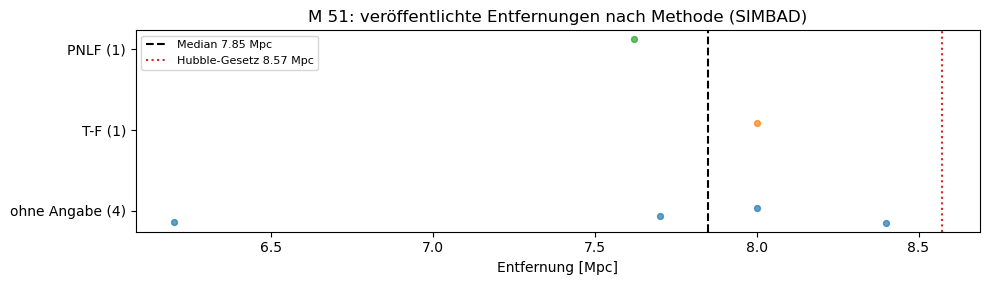

In [4]:
match = galaxies.loc[galaxies["main_id"] == SELECTED_GALAXY]
if len(match) == 0:
    raise ValueError(f"'{SELECTED_GALAXY}' nicht gefunden; Schreibweise prüfen (Leerzeichen in 'M 51').")
info = match.iloc[0]
coord = SkyCoord(info["ra"], info["dec"], unit="deg")
a_arcmin = info["galdim_majaxis"]                                          # Durchmesser große Achse [']
b_arcmin = info["galdim_minaxis"] if pd.notna(info["galdim_minaxis"]) else a_arcmin
pa_deg = float(info["galdim_angle"]) if pd.notna(info["galdim_angle"]) else 0.0   # von Norden über Osten

# Entfernungen, die nicht aus der Rotverschiebung stammen (Cepheiden, TRGB, PNLF, Tully-Fisher, ...)
dist = Simbad.query_tap(f'''
SELECT m.dist, m.unit, m.method, m.bibcode
FROM mesDistance AS m JOIN ident AS i ON i.oidref = m.oidref
WHERE i.id = '{SELECTED_GALAXY}'
''').to_pandas()
to_mpc = {"Mpc": 1.0, "kpc": 1e-3, "pc": 1e-6}
dist["dist_mpc"] = dist["dist"] * dist["unit"].str.strip().map(to_mpc)
dist = dist[dist["method"].str.strip() != "redshift"].dropna(subset=["dist_mpc"])
dist_mpc = dist["dist_mpc"].median()

# Fluchtgeschwindigkeit aus NED
ned, v_rec = None, info["rvz_radvel"]
for attempt in range(2):                                      # NED antwortet manchmal langsam
    try:
        ned = Ned.query_object(SELECTED_GALAXY).to_pandas().iloc[0]
        v_rec = float(ned["Velocity"])
        break
    except Exception as e:
        error = e
if ned is None:
    print(f"NED-Abfrage fehlgeschlagen ({error}); nehme die Geschwindigkeit aus SIMBAD")

kpc_per_arcmin = dist_mpc * 1e3 * np.deg2rad(1 / 60)          # Herleitung, Punkt 1
size_kpc = a_arcmin * kpc_per_arcmin
M_V = info["vmag"] - 5 * np.log10(dist_mpc * 1e6 / 10)        # Herleitung, Punkt 2
d_hubble = v_rec / H0

print(f"Galaxie:               {SELECTED_GALAXY}" + (f"   (NED: {ned['Object Name']}, Typ {ned['Type']})" if ned is not None else ""))
print(f"Objekttyp:             {info['typ']}   |   Hubble-Typ: {info['morph_type']}")
print(f"Koordinaten:           {coord.to_string('hmsdms', precision=1)}")
print(f"Helligkeit:            V = {info['vmag']:.2f}   B-V = {info['b_v']:.2f}   K = {info['kmag']:.2f}")
print(f"Scheinbare Größe:      {a_arcmin:.1f}' x {b_arcmin:.1f}'   (PA {pa_deg:.0f}°)")
print(f"Fluchtgeschwindigkeit: {v_rec:.0f} km/s (NED; SIMBAD: {info['rvz_radvel']:.0f} km/s)")
print(f"Entfernung:            {dist_mpc:.2f} Mpc = {dist_mpc * 3.26156:.1f} Millionen Lichtjahre "
      f"(Median aus {len(dist)} Messungen ohne Rotverschiebung)")
print(f"Maßstab:               1' = {kpc_per_arcmin:.2f} kpc")
print(f"Durchmesser:           {size_kpc:.1f} kpc = {size_kpc * 3261.56:,.0f} Lichtjahre")
print(f"Absolute Helligkeit:   M_V = {M_V:.2f}")
print(f"\nHubble-Gesetz: v/H0 = {d_hubble:.2f} Mpc gegen die Entfernungsleiter {dist_mpc:.2f} Mpc")
print(f"Eigenbewegung: v - H0·D = {v_rec - H0 * dist_mpc:+.0f} km/s")

if len(dist):
    rng = np.random.default_rng(0)
    methods = dist["method"].str.strip().str.upper().replace("", "ohne Angabe")
    order = methods.value_counts().index
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(order) + 1.6))
    for j, m in enumerate(order):
        d = dist.loc[methods == m, "dist_mpc"]
        ax.scatter(d, j + rng.uniform(-0.15, 0.15, len(d)), s=18, alpha=0.7)
    ax.axvline(dist_mpc, color="black", ls="--", label=f"Median {dist_mpc:.2f} Mpc")
    if d_hubble > 0:
        ax.axvline(d_hubble, color="tab:red", ls=":", label=f"Hubble-Gesetz {d_hubble:.2f} Mpc")
    ax.set_yticks(range(len(order)), [f"{m} ({(methods == m).sum()})" for m in order])
    ax.set_xlabel("Entfernung [Mpc]")
    ax.set_title(f"{SELECTED_GALAXY}: veröffentlichte Entfernungen nach Methode (SIMBAD)")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

##### *3. Bilder in sechs Wellenlängenbereichen*

Wie sieht dieselbe Galaxie im Ultravioletten, im Optischen und im Infraroten aus, und welche Bestandteile treten in welchem Band hervor?

Lade 6 Bilder, 400x400 Pixel, Feld 14.5 arcmin ...


   GALEX Near UV  (400, 400)
   DSS2 Blue      (400, 400)
   DSS2 Red       (400, 400)
   2MASS-K        (400, 400)
   WISE 3.4       (400, 400)
   WISE 12        (400, 400)
Pixelgröße 2.17"


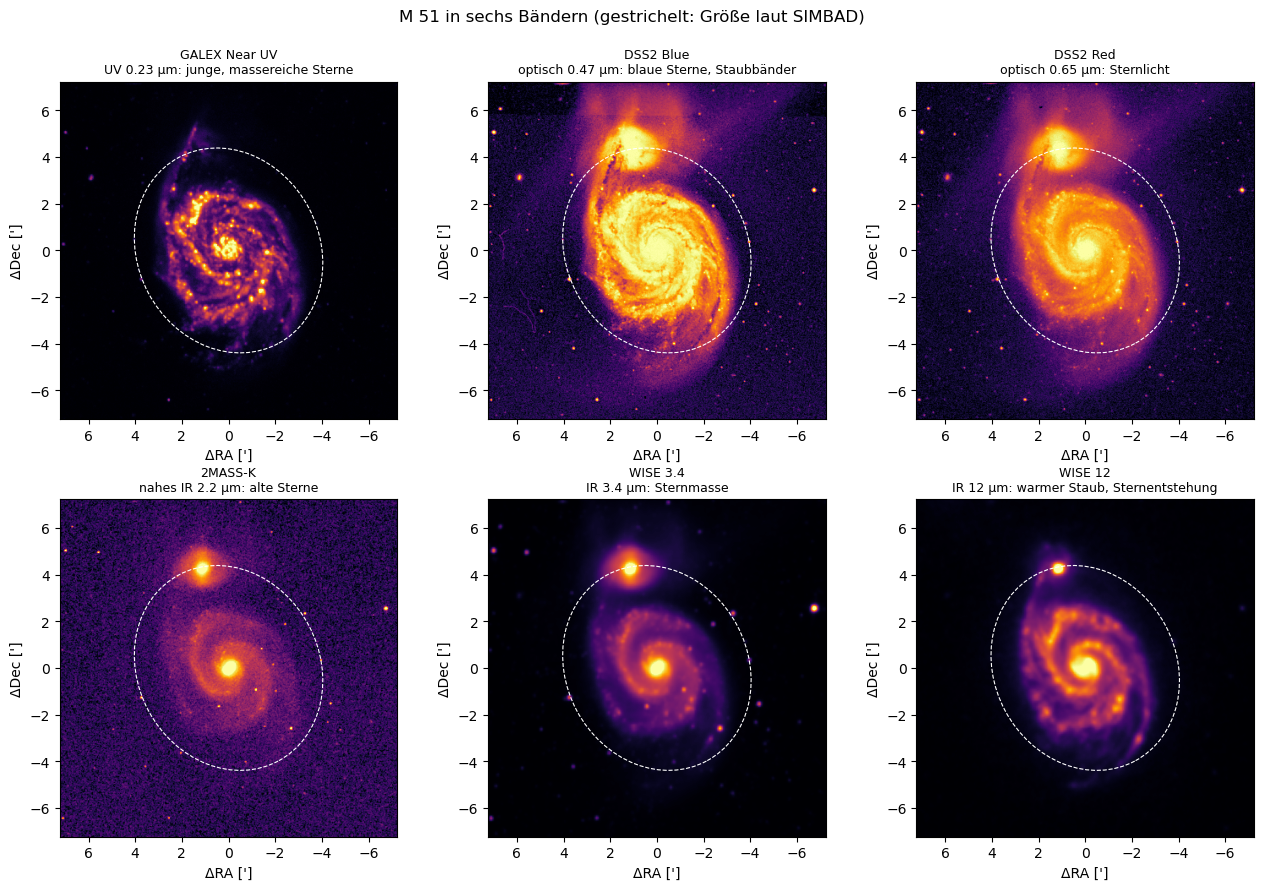

In [5]:
SURVEYS = {
    "GALEX Near UV": "UV 0.23 µm: junge, massereiche Sterne",
    "DSS2 Blue":     "optisch 0.47 µm: blaue Sterne, Staubbänder",
    "DSS2 Red":      "optisch 0.65 µm: Sternlicht",
    "2MASS-K":       "nahes IR 2.2 µm: alte Sterne",
    "WISE 3.4":      "IR 3.4 µm: Sternmasse",
    "WISE 12":       "IR 12 µm: warmer Staub, Sternentstehung",
}
FOV_FACTOR = 1.6    # Bildfeld = 1.6 x Durchmesser
PIXELS = 400

fov = FOV_FACTOR * a_arcmin * u.arcmin
print(f"Lade {len(SURVEYS)} Bilder, {PIXELS}x{PIXELS} Pixel, Feld {fov:.1f} ...")
hdus = SkyView.get_images(position=coord, survey=list(SURVEYS), pixels=PIXELS, width=fov, height=fov)
images = {}
for name, hdul in zip(SURVEYS, hdus):
    data = hdul[0].data.astype(float)
    if np.nanmax(data) == np.nanmin(data):
        print(f"   {name:14s} keine Abdeckung")
        continue
    images[name] = data
    print(f"   {name:14s} {data.shape}")

pix_arcmin = abs(hdus[0][0].header["CDELT1"]) * 60                  # Bogenminuten pro Pixel
half = PIXELS / 2 * pix_arcmin
extent = [half, -half, -half, half]                                  # Osten links, Norden oben
print(f"Pixelgröße {pix_arcmin * 60:.2f}\"")

def stretch(img, lo=1, hi=99.8):
    # Asinh-Streckung zwischen zwei Perzentilen (wie in ds9 oder Aladin)
    vmin, vmax = np.nanpercentile(img, [lo, hi])
    x = np.clip((img - vmin) / (vmax - vmin), 0, 1)
    return np.arcsinh(10 * x) / np.arcsinh(10)

def catalog_ellipse(color="white"):
    return Ellipse((0, 0), width=b_arcmin, height=a_arcmin, angle=-pa_deg, fill=False, ec=color, ls="--", lw=0.8)

ncol = 3
nrow = int(np.ceil(len(images) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 4.4 * nrow))
for ax, (name, img) in zip(axes.flat, images.items()):
    ax.imshow(stretch(img), origin="lower", cmap="inferno", extent=extent)
    ax.add_patch(catalog_ellipse())
    ax.set_title(f"{name}\n{SURVEYS[name]}", fontsize=9)
    ax.set_xlabel("ΔRA [']")
    ax.set_ylabel("ΔDec [']")
for ax in list(axes.flat)[len(images):]:
    ax.axis("off")
fig.suptitle(f"{SELECTED_GALAXY} in sechs Bändern (gestrichelt: Größe laut SIMBAD)", y=1.0)
fig.tight_layout()
plt.show()

Wo liegen junge Sterne, alte Sterne und warmer Staub relativ zueinander? Links das optische Farbbild, rechts ein Falschfarbenbild aus drei Bändern: Rot ist warmer Staub (12 µm), Grün sind alte Sterne (3.4 µm), Blau junge Sterne (UV).

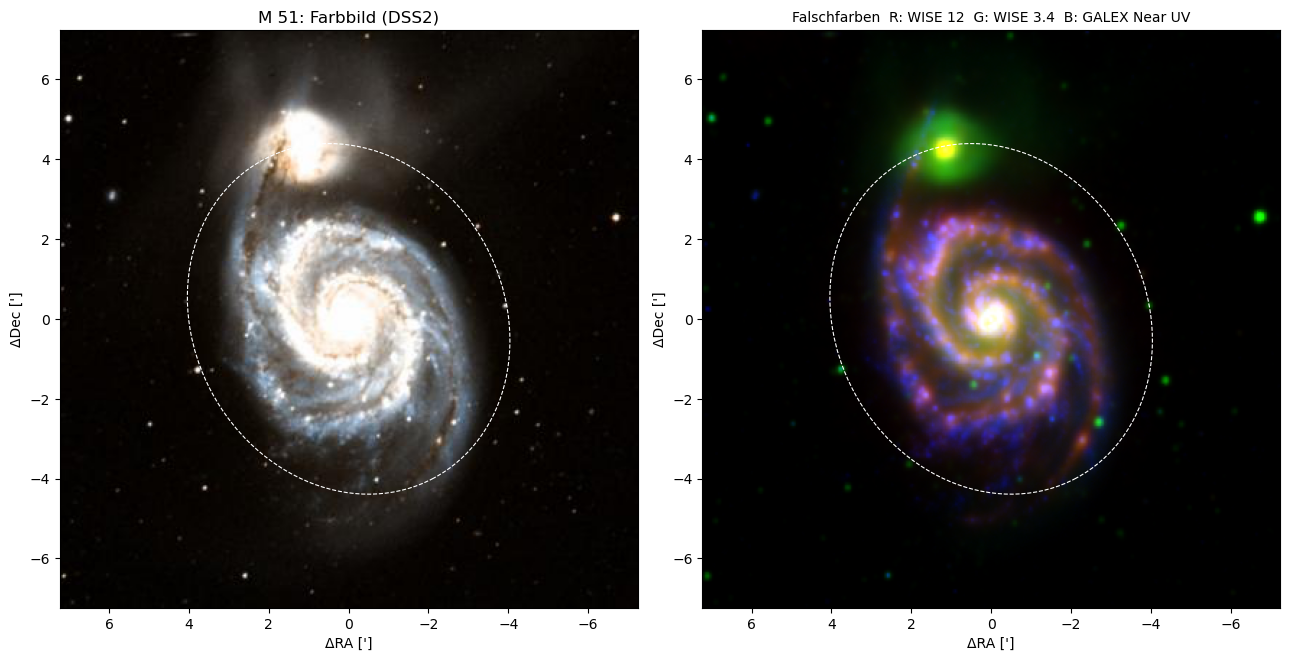

In [6]:
HIPS = "CDS/P/DSS2/color"   # Alternativen: "CDS/P/PanSTARRS/DR1/color-z-zg-g" (Dec > -30°), "CDS/P/SDSS9/color"
optical = hips2fits.query(hips=HIPS, width=PIXELS, height=PIXELS, ra=Angle(info["ra"] * u.deg),
                          dec=Angle(info["dec"] * u.deg), fov=Angle(fov), projection="TAN", format="jpg")

CHANNELS = ["WISE 12", "WISE 3.4", "GALEX Near UV"]
available = [c for c in CHANNELS if c in images]
if len(available) < 3:                       # ohne GALEX: DSS2 Blue als blauer Kanal
    available = [c for c in ["WISE 12", "WISE 3.4", "DSS2 Blue"] if c in images]
rgb = np.dstack([stretch(images[c], lo=50, hi=99.8) for c in available])   # lo=50: Himmel wird schwarz

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
axes[0].imshow(optical, extent=extent)       # die Zeilen des JPG laufen von Norden nach Süden
axes[0].set_title(f"{SELECTED_GALAXY}: Farbbild ({HIPS.split('/')[2]})")
axes[1].imshow(rgb, origin="lower", extent=extent)
axes[1].set_title(f"Falschfarben  R: {available[0]}  G: {available[1]}  B: {available[2]}", fontsize=10)
for ax in axes:
    ax.add_patch(catalog_ellipse())
    ax.set_xlabel("ΔRA [']")
    ax.set_ylabel("ΔDec [']")
fig.tight_layout()
plt.show()

#### **Reduktion**

##### *4. Himmelshintergrund und radiales Profil*

Wie hell ist die Galaxie in Abhängigkeit vom Radius, wenn man über Ellipsen mittelt und den Himmelshintergrund abzieht? Gemessen wird bei 3.4 µm, wo das Licht der Sternmasse folgt und Staub kaum stört.

Himmel (Median außerhalb 1.1 a): 2.501, robuste Streuung 0.343  [WISE 3.4-Einheiten]
Profil: 40 Ringe bis 5.88'; Achsenverhältnis q = 0.86, PA = 28°
Zentrum 383.5, bei a: 3.70; Profil fällt unter 3 σ des Himmels bei 4.78'


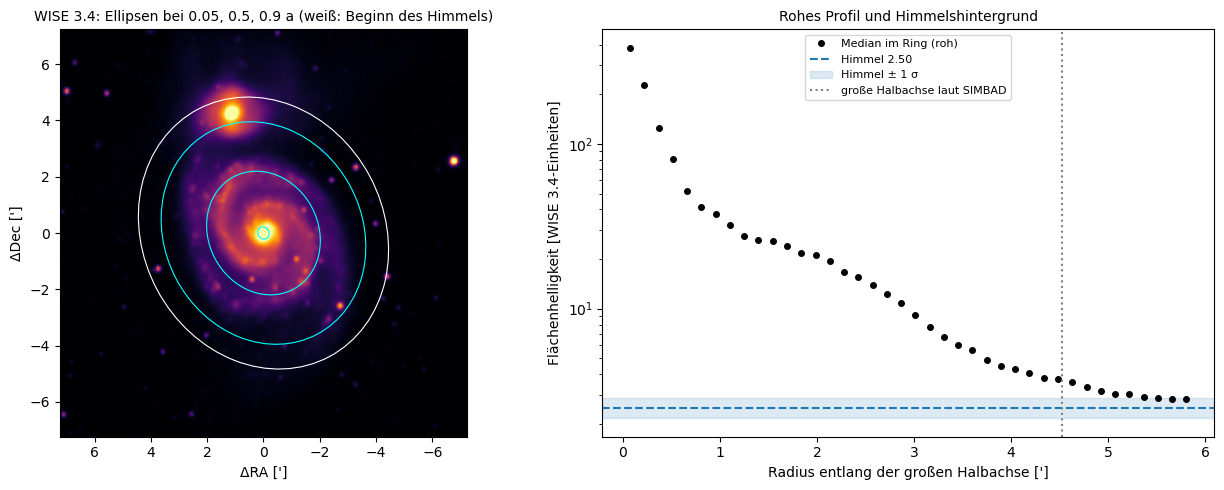

In [7]:
BAND = "WISE 3.4"
N_BINS = 40

img = images[BAND]
ny, nx = img.shape
yy, xx = np.mgrid[:ny, :nx]
dx = -(xx - (nx - 1) / 2) * pix_arcmin            # Bogenminuten, Osten positiv
dy = (yy - (ny - 1) / 2) * pix_arcmin             # Bogenminuten, Norden positiv

# Elliptischer Radius (Herleitung, Punkt 4)
pa = np.deg2rad(pa_deg)
q = b_arcmin / a_arcmin
x_a = dx * np.sin(pa) + dy * np.cos(pa)
x_b = dx * np.cos(pa) - dy * np.sin(pa)
r_ell = np.hypot(x_a, x_b / q)                    # Radius entlang der großen Halbachse [']

a_cat = a_arcmin / 2                               # große Halbachse laut Katalog
def robust_std(x):
    # Streuung aus der mittleren absoluten Abweichung; Sterne im Feld blähen die Standardabweichung auf
    x = x[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x)))

sky_region = r_ell > 1.1 * a_cat
sky = np.nanmedian(img[sky_region])
sky_noise = robust_std(img[sky_region])

def ring_median(image, r, edges):
    # Median in elliptischen Ringen; NaN, wo ein Ring keine gültigen Pixel hat
    out = np.full(len(edges) - 1, np.nan)
    for k, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        v = image[(r >= lo) & (r < hi)]
        v = v[np.isfinite(v)]
        if v.size:
            out[k] = np.median(v)
    return out

edges = np.linspace(0, 1.3 * a_cat, N_BINS + 1)
r_mid = 0.5 * (edges[1:] + edges[:-1])
raw = ring_median(img, r_ell, edges)
prof = raw - sky

print(f"Himmel (Median außerhalb 1.1 a): {sky:.3f}, robuste Streuung {sky_noise:.3f}  [{BAND}-Einheiten]")
print(f"Profil: {N_BINS} Ringe bis {edges[-1]:.2f}'; Achsenverhältnis q = {q:.2f}, PA = {pa_deg:.0f}°")
print(f"Zentrum {raw[0]:.1f}, bei a: {np.interp(a_cat, r_mid, raw):.2f}; Profil fällt unter 3 σ des Himmels bei "
      f"{r_mid[np.argmax(prof < 3 * sky_noise)]:.2f}'")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(stretch(img), origin="lower", cmap="inferno", extent=extent)
for f, col in [(0.05, "cyan"), (0.5, "cyan"), (0.9, "cyan"), (1.1, "white")]:
    axes[0].add_patch(Ellipse((0, 0), 2 * f * a_cat * q, 2 * f * a_cat, angle=-pa_deg, fill=False, ec=col, lw=0.8))
axes[0].set_title(f"{BAND}: Ellipsen bei 0.05, 0.5, 0.9 a (weiß: Beginn des Himmels)", fontsize=10)
axes[0].set_xlabel("ΔRA [']")
axes[0].set_ylabel("ΔDec [']")
axes[1].semilogy(r_mid, raw, "o", c="black", ms=4, label="Median im Ring (roh)")
axes[1].axhline(sky, color="tab:blue", ls="--", label=f"Himmel {sky:.2f}")
axes[1].axhspan(sky - sky_noise, sky + sky_noise, color="tab:blue", alpha=0.15, label="Himmel ± 1 σ")
axes[1].axvline(a_cat, color="grey", ls=":", label="große Halbachse laut SIMBAD")
axes[1].set_xlabel("Radius entlang der großen Halbachse [']")
axes[1].set_ylabel(f"Flächenhelligkeit [{BAND}-Einheiten]")
axes[1].set_title("Rohes Profil und Himmelshintergrund", fontsize=10)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

#### **Eigene Messung**

##### *5. Das Sérsic-Profil*

Welcher Sérsic-Index beschreibt das Profil, und passt er zum Hubble-Typ? Angepasst wird zwischen 0.05 und 0.9 der großen Halbachse: innen stört die Auflösung von WISE (etwa 6″), außen das Rauschen des Himmels.

Sérsic-Fit in WISE 3.4 an 26 Ringe
  Sérsic-Index:     n = 0.88 ± 0.12   ->  scheibendominiert (Spirale, S0)
  Hubble-Typ:       SA  (SIMBAD)
  Effektivradius:   r_e = 1.70' ± 0.06' = 3.89 kpc
  Skalenlänge:      h ≈ r_e/1.678 = 1.02' = 2.32 kpc  (Milchstraße etwa 2.6 kpc)
  Neigung:          q = 0.86  ->  i = arccos q = 31° (dünne Scheibe)
  Residuen:         rms in ln I = 0.193


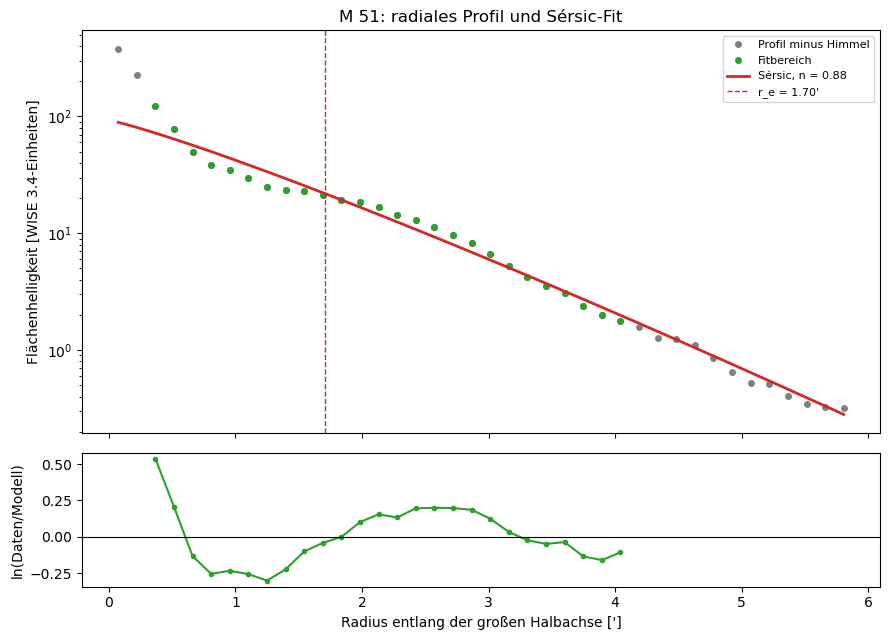

In [8]:
R_FIT = (0.05, 0.9)   # Fitbereich in Einheiten der großen Halbachse

def sersic(r, I_e, r_e, n):
    b_n = gammaincinv(2 * n, 0.5)                 # Herleitung, Punkt 5
    return I_e * np.exp(-b_n * ((r / r_e) ** (1 / n) - 1))

sel = (r_mid > R_FIT[0] * a_cat) & (r_mid < R_FIT[1] * a_cat) & (prof > 0)
p0 = [np.log(max(np.interp(a_cat / 3, r_mid, prof), 1e-6)), a_cat / 3, 2.0]
popt, pcov = curve_fit(lambda r, lnI, r_e, n: np.log(sersic(r, np.exp(lnI), r_e, n)),
                       r_mid[sel], np.log(prof[sel]), p0=p0, bounds=([-np.inf, 0.01, 0.3], [np.inf, 5 * a_cat, 10]))
I_e, r_e, n = np.exp(popt[0]), popt[1], popt[2]
n_err, re_err = np.sqrt(pcov[2, 2]), np.sqrt(pcov[1, 1])
resid_single = np.log(prof[sel]) - np.log(sersic(r_mid[sel], I_e, r_e, n))

kind = ("scheibendominiert (Spirale, S0)" if n < 2 else
        "Übergang (Bulge und Scheibe)" if n < 2.5 else "sphäroiddominiert (elliptisch, klassischer Bulge)")
print(f"Sérsic-Fit in {BAND} an {sel.sum()} Ringe")
print(f"  Sérsic-Index:     n = {n:.2f} ± {n_err:.2f}   ->  {kind}")
print(f"  Hubble-Typ:       {info['morph_type']}  (SIMBAD)")
print(f"  Effektivradius:   r_e = {r_e:.2f}' ± {re_err:.2f}' = {r_e * kpc_per_arcmin:.2f} kpc")
if n < 2:
    h_single = r_e / gammaincinv(2, 0.5)          # für n = 1 ist r_e = 1.678 h
    print(f"  Skalenlänge:      h ≈ r_e/1.678 = {h_single:.2f}' = {h_single * kpc_per_arcmin:.2f} kpc  (Milchstraße etwa 2.6 kpc)")
print(f"  Neigung:          q = {q:.2f}  ->  i = arccos q = {np.rad2deg(np.arccos(np.clip(q, 0, 1))):.0f}° (dünne Scheibe)")
print(f"  Residuen:         rms in ln I = {np.sqrt(np.mean(resid_single ** 2)):.3f}")

fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].semilogy(r_mid, np.where(prof > 0, prof, np.nan), "o", c="grey", ms=4, label="Profil minus Himmel")
axes[0].semilogy(r_mid[sel], prof[sel], "o", c="tab:green", ms=4, label="Fitbereich")
r_plot = np.linspace(r_mid[0], r_mid[-1], 300)
axes[0].semilogy(r_plot, sersic(r_plot, I_e, r_e, n), c="tab:red", lw=2, label=f"Sérsic, n = {n:.2f}")
axes[0].axvline(r_e, color="tab:red", ls="--", lw=1, label=f"r_e = {r_e:.2f}'")
axes[0].set_ylabel(f"Flächenhelligkeit [{BAND}-Einheiten]")
axes[0].set_title(f"{SELECTED_GALAXY}: radiales Profil und Sérsic-Fit")
axes[0].legend(fontsize=8)
axes[1].plot(r_mid[sel], resid_single, "o-", c="tab:green", ms=3)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xlabel("Radius entlang der großen Halbachse [']")
axes[1].set_ylabel("ln(Daten/Modell)")
fig.tight_layout()
plt.show()

##### *6. Die Farbkarte*

Wo in der Galaxie entstehen gerade Sterne? Die Karte zeigt NUV − W1, das Verhältnis von UV-Licht junger Sterne zum Licht der Sternmasse, relativ zum Median der Galaxie.

Pixel mit beiden Bändern über 3 σ: 36527
NUV - W1 im Zentrum (r < 0.1 a): +0.61 mag, in der Scheibe (0.3-0.7 a): -0.13 mag
Die Scheibe ist um 0.74 mag blauer als das Zentrum


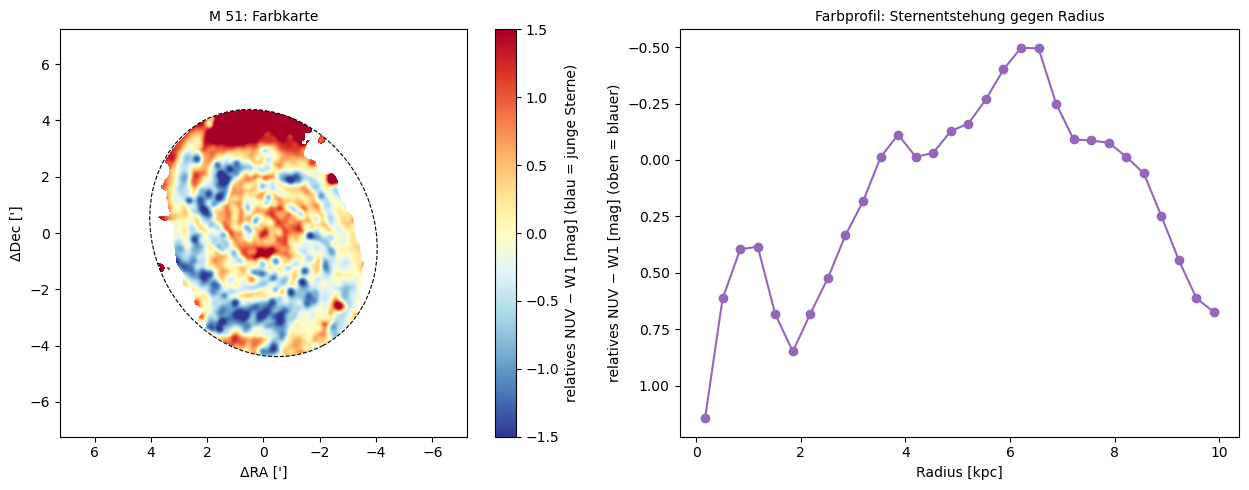

In [9]:
colour_ok = "GALEX Near UV" in images and "WISE 3.4" in images
if not colour_ok:
    print("Kein GALEX-Bild für diese Galaxie; die Farbkarte entfällt.")
else:
    nuv = gaussian_filter(images["GALEX Near UV"], 2)       # auf ähnliche Auflösung glätten
    w1 = gaussian_filter(images["WISE 3.4"], 2)
    nuv_sky, w1_sky = np.nanmedian(nuv[sky_region]), np.nanmedian(w1[sky_region])
    nuv_n, w1_n = robust_std(nuv[sky_region]), robust_std(w1[sky_region])
    det = ((nuv - nuv_sky) > 3 * nuv_n) & ((w1 - w1_sky) > 3 * w1_n) & (r_ell < a_cat)
    colour = np.full(img.shape, np.nan)
    colour[det] = -2.5 * np.log10((nuv - nuv_sky)[det] / (w1 - w1_sky)[det])   # Herleitung, Punkt 8
    colour -= np.nanmedian(colour)                                              # nur relativ
    c_prof = ring_median(colour, r_ell, edges)
    in_ring = np.digitize(r_ell, edges) - 1
    covered = np.array([det[in_ring == k].mean() if (in_ring == k).any() else 0 for k in range(len(r_mid))])
    c_prof[covered < 0.5] = np.nan                                              # Ringe, die nur zum Teil gemessen sind
    inner = np.nanmedian(c_prof[r_mid < 0.1 * a_cat])                          # Zentrum (Bulge)
    outer = np.nanmedian(c_prof[(r_mid > 0.3 * a_cat) & (r_mid < 0.7 * a_cat)])  # Scheibe, ohne den Rand
    print(f"Pixel mit beiden Bändern über 3 σ: {det.sum()}")
    print(f"NUV - W1 im Zentrum (r < 0.1 a): {inner:+.2f} mag, in der Scheibe (0.3-0.7 a): {outer:+.2f} mag")
    print(f"Die Scheibe ist um {inner - outer:.2f} mag blauer als das Zentrum")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    im = axes[0].imshow(colour, origin="lower", cmap="RdYlBu_r", extent=extent, vmin=-1.5, vmax=1.5)
    axes[0].add_patch(catalog_ellipse("black"))
    fig.colorbar(im, ax=axes[0], label="relatives NUV − W1 [mag] (blau = junge Sterne)")
    axes[0].set_title(f"{SELECTED_GALAXY}: Farbkarte", fontsize=10)
    axes[0].set_xlabel("ΔRA [']")
    axes[0].set_ylabel("ΔDec [']")
    axes[1].plot(r_mid * kpc_per_arcmin, c_prof, "o-", c="tab:purple")
    axes[1].invert_yaxis()
    axes[1].set_xlabel("Radius [kpc]")
    axes[1].set_ylabel("relatives NUV − W1 [mag] (oben = blauer)")
    axes[1].set_title("Farbprofil: Sternentstehung gegen Radius", fontsize=10)
    fig.tight_layout()
    plt.show()

#### **Modell und Fit**

##### *7. Bulge und Scheibe*

Beschreiben ein Sérsic-Bulge und eine exponentielle Scheibe das Profil besser als ein einzelnes Sérsic-Profil, und welchen Anteil am Licht hat der Bulge? Radien unter 0.2′ bleiben weg, weil WISE dort nicht auflöst.

Bulge und Scheibe in WISE 3.4 (Radien 0.2' bis 4.1')
  Bulge:   n = 0.50, r_e = 0.25' = 0.57 kpc   (n an der Grenze des Fits: Bulge kaum aufgelöst)
  Scheibe: h = 1.06' = 2.43 kpc
  B/T = 0.09   (Hubble-Typ SA)
  Residuen (rms in ln I): ein Sérsic-Profil 0.274  ->  Bulge und Scheibe 0.163


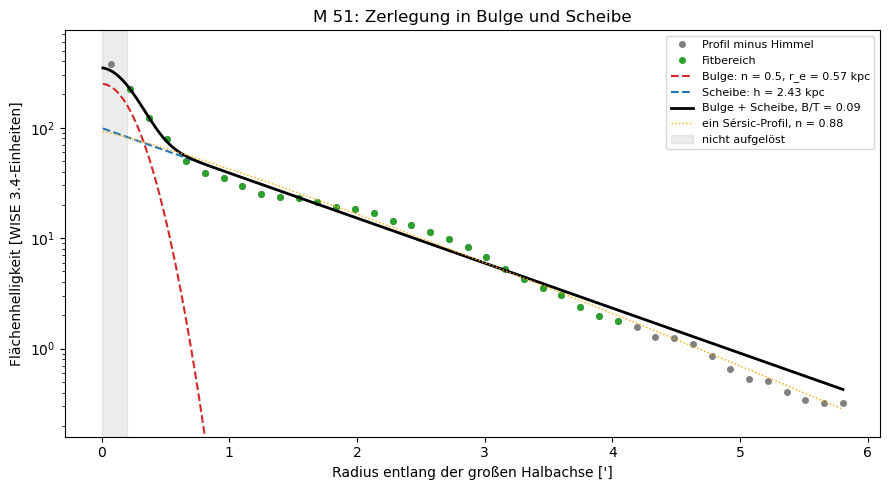

In [10]:
PSF_ARCMIN = 0.2      # WISE 3.4 µm löst etwa 6" auf, die SkyView-Pixel sind etwa 2"

def bulge_disk(r, lnIe, r_e_b, n_b, lnI0, h):
    return sersic(r, np.exp(lnIe), r_e_b, n_b) + np.exp(lnI0) * np.exp(-r / h)

sel2 = (r_mid > PSF_ARCMIN) & (r_mid < R_FIT[1] * a_cat) & (prof > 0)
p0_bd = [np.log(prof[sel2][0]), 0.1 * a_cat, 2.0, np.log(prof[sel2][len(prof[sel2]) // 3]), 0.3 * a_cat]
bd_bounds = ([-np.inf, 0.01, 0.5, -np.inf, 0.02], [np.inf, 0.5 * a_cat, 8.0, np.inf, 2 * a_cat])
p_bd, _ = curve_fit(lambda r, *p: np.log(bulge_disk(r, *p)), r_mid[sel2], np.log(prof[sel2]),
                    p0=p0_bd, bounds=bd_bounds, maxfev=20000)
lnIe_b, re_b, n_b, lnI0_d, h_d = p_bd

# Gesamtlicht der Komponenten (Herleitung, Punkte 5 bis 7)
b_nb = gammaincinv(2 * n_b, 0.5)
L_bulge = 2 * np.pi * q * n_b * np.exp(lnIe_b) * re_b ** 2 * np.exp(b_nb) * gamma_fn(2 * n_b) / b_nb ** (2 * n_b)
L_disk = 2 * np.pi * q * np.exp(lnI0_d) * h_d ** 2
BT = L_bulge / (L_bulge + L_disk)
rms_single = np.sqrt(np.mean((np.log(prof[sel2]) - np.log(sersic(r_mid[sel2], I_e, r_e, n))) ** 2))
rms_double = np.sqrt(np.mean((np.log(prof[sel2]) - np.log(bulge_disk(r_mid[sel2], *p_bd))) ** 2))

at_bound = n_b < 0.55 or n_b > 7.9
print(f"Bulge und Scheibe in {BAND} (Radien {PSF_ARCMIN}' bis {R_FIT[1] * a_cat:.1f}')")
print(f"  Bulge:   n = {n_b:.2f}, r_e = {re_b:.2f}' = {re_b * kpc_per_arcmin:.2f} kpc"
      + ("   (n an der Grenze des Fits: Bulge kaum aufgelöst)" if at_bound else ""))
print(f"  Scheibe: h = {h_d:.2f}' = {h_d * kpc_per_arcmin:.2f} kpc")
print(f"  B/T = {BT:.2f}   (Hubble-Typ {info['morph_type']})")
print(f"  Residuen (rms in ln I): ein Sérsic-Profil {rms_single:.3f}  ->  Bulge und Scheibe {rms_double:.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogy(r_mid, np.where(prof > 0, prof, np.nan), "o", c="grey", ms=4, label="Profil minus Himmel")
ax.semilogy(r_mid[sel2], prof[sel2], "o", c="tab:green", ms=4, label="Fitbereich")
rp = np.linspace(0.01, r_mid[-1], 300)
ax.semilogy(rp, sersic(rp, np.exp(lnIe_b), re_b, n_b), c="tab:red", ls="--",
            label=f"Bulge: n = {n_b:.1f}, r_e = {re_b * kpc_per_arcmin:.2f} kpc")
ax.semilogy(rp, np.exp(lnI0_d) * np.exp(-rp / h_d), c="tab:blue", ls="--", label=f"Scheibe: h = {h_d * kpc_per_arcmin:.2f} kpc")
ax.semilogy(rp, bulge_disk(rp, *p_bd), c="black", lw=2, label=f"Bulge + Scheibe, B/T = {BT:.2f}")
ax.semilogy(rp, sersic(rp, I_e, r_e, n), c="orange", lw=1, ls=":", label=f"ein Sérsic-Profil, n = {n:.2f}")
ax.axvspan(0, PSF_ARCMIN, color="grey", alpha=0.15, label="nicht aufgelöst")
ax.set_ylim(np.nanmin(prof[prof > 0]) * 0.5, np.nanmax(prof) * 2)
ax.set_xlabel("Radius entlang der großen Halbachse [']")
ax.set_ylabel(f"Flächenhelligkeit [{BAND}-Einheiten]")
ax.set_title(f"{SELECTED_GALAXY}: Zerlegung in Bulge und Scheibe")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

#### **Eigene Messung gegen den Katalog**

##### *8. Vergleich mit der S4G-Zerlegung*

Stimmen Sérsic-Index, Bulge-Anteil und Skalenlänge mit der Zerlegung von Salo et al. (2015) überein? S4G misst bei 3.6 µm mit Spitzer (Auflösung 1.7″), passt die Modelle zweidimensional an das ganze Bild an und berücksichtigt die Punktverbreiterung; hier wird ein eindimensionales Profil aus WISE-Bildern mit 6″ Auflösung angepasst.

In [11]:
viz = Vizier(columns=["**"], row_limit=-1)
hit = viz.query_region(coord, radius=1 * u.arcmin, catalog="J/ApJS/219/4/galaxies")
if len(hit) == 0:
    print(f"{SELECTED_GALAXY} ist nicht in S4G (nur Galaxien näher als 40 Mpc mit HI-Geschwindigkeit, "
          "elliptische Galaxien fehlen meist)")
else:
    s4 = hit[0].to_pandas()
    s4 = s4.iloc[[np.argmin(coord.separation(SkyCoord(s4["_RA"], s4["_DE"], unit="deg")).arcsec)]].iloc[0]
    comps = viz.query_constraints(catalog="J/ApJS/219/4/table7", Name=s4["Name"])[0].to_pandas()
    bul = comps[(comps["C"].str.strip() == "B") & (comps["Fn"].str.strip() == "sersic")]
    disk = comps[comps["Fn"].str.strip().isin(["expdisk", "edgedisk"])]
    h_s4 = (disk["hr3"].fillna(disk["hr2"]).iloc[0] / 60) if len(disk) else np.nan
    print(f"S4G: {s4['Name']}, Modell '{comps['Mod'].iloc[0].strip()}' mit den Komponenten "
          f"{', '.join(comps['C'].str.strip() + ' (' + comps['Fn'].str.strip() + ')')}, Qualität {comps['Q'].iloc[0]}")

    # Ein Sérsic-Profil über den ganzen Radius, wie bei S4G ohne inneren Schnitt
    sel_all = (r_mid < R_FIT[1] * a_cat) & (prof > 0)
    p_all, _ = curve_fit(lambda r, lnI, r_e, n: np.log(sersic(r, np.exp(lnI), r_e, n)), r_mid[sel_all],
                         np.log(prof[sel_all]), p0=p0, bounds=([-np.inf, 0.01, 0.3], [np.inf, 5 * a_cat, 10]))

    rows = [("ein Sérsic-Profil: n", f"{n:.2f}", f"{p_all[2]:.2f}", f"{s4['n']:.2f}"),
            ("ein Sérsic-Profil: r_e [']", f"{r_e:.2f}", f"{p_all[1]:.2f}", f"{s4['Re'] / 60:.2f}"),
            ("Achsenverhältnis q", f"{q:.2f} (SIMBAD)", "", f"{s4['q']:.2f}"),
            ("B/T", f"{BT:.2f}", "", f"{bul['f1'].iloc[0]:.2f}" if len(bul) else "0 (kein Bulge)"),
            ("Bulge: n", f"{n_b:.2f}", "", f"{bul['n'].iloc[0]:.2f}" if len(bul) else "-"),
            ("Bulge: r_e [']", f"{re_b:.2f}", "", f"{bul['Re'].iloc[0] / 60:.2f}" if len(bul) else "-"),
            ("Scheibe: h [']", f"{h_d:.2f}", "", f"{h_s4:.2f}"),
            ("Scheibe: h [kpc]", f"{h_d * kpc_per_arcmin:.2f}", "", f"{h_s4 * kpc_per_arcmin:.2f}")]
    table = pd.DataFrame(rows, columns=["Größe", "eigen (0.05-0.9 a)", "eigen (0-0.9 a)", "S4G"])
    print(f"\nEntfernung für beide: {dist_mpc:.2f} Mpc\n")
    print(table.to_string(index=False))

S4G: NGC5194, Modell '_bd' mit den Komponenten B (sersic), D (expdisk), Qualität 5

Entfernung für beide: 7.85 Mpc

                     Größe eigen (0.05-0.9 a) eigen (0-0.9 a)  S4G
      ein Sérsic-Profil: n               0.88            1.83 3.87
ein Sérsic-Profil: r_e [']               1.70            1.71 4.03
        Achsenverhältnis q      0.86 (SIMBAD)                 0.79
                       B/T               0.09                 0.13
                  Bulge: n               0.50                 1.00
            Bulge: r_e [']               0.25                 0.36
            Scheibe: h [']               1.06                 1.40
          Scheibe: h [kpc]               2.43                 3.20


Ergebnis beim Lauf vom 2026-10-12 (M 51):

- **Katalog:** 129 Galaxien sind heller als V = 10.5 und größer als 3′. SIMBAD führt M 51 als Seyfert-2-Galaxie vom Hubble-Typ SA, NED als Galaxienpaar.
- **Entfernung:** Sechs Messungen ohne Rotverschiebung liegen zwischen 6.2 und 8.4 Mpc, der Median ist 7.85 Mpc (PNLF 7.6 Mpc, Tully-Fisher 8.0 Mpc). Damit ist 1′ = 2.28 kpc, der Durchmesser 20.7 kpc und $M_V = -21.1$. Das Hubble-Gesetz gibt mit der NED-Geschwindigkeit von 600 km/s 8.57 Mpc, also eine Eigenbewegung von +50 km/s. SIMBAD nennt 523 km/s; schon die gemessene Geschwindigkeit unterscheidet sich zwischen den Datenbanken um 77 km/s, das allein ändert $v/H_0$ um 1.1 Mpc.
- **Bilder:** Im UV leuchten nur die Spiralarme mit ihren jungen Sternhaufen, bei 3.4 µm ist die Galaxie glatt mit hellem Kern, bei 12 µm zeichnet der warme Staub wieder die Arme nach. Der Begleiter NGC 5195 ist im Infraroten hell und im UV schwach.
- **Profil:** Der Himmel liegt bei 2.50 mit einer robusten Streuung von 0.34; das Profil fällt bei 4.8′ unter 3 σ, nahe der großen Halbachse laut SIMBAD (4.5′).
- **Sérsic-Profil:** $n = 0.88 \pm 0.12$ und $r_e = 1.70' = 3.9$ kpc, also scheibendominiert; daraus folgt $h \approx 2.3$ kpc. Die Residuen sind nicht zufällig: Das Zentrum liegt über dem Modell (der Bulge), bei 1′ darunter, zwischen 2′ und 3′ wieder darüber (die Spiralarme).
- **Farbe:** Die Scheibe (0.3–0.7 der großen Halbachse) ist in NUV − W1 um 0.74 mag blauer als das Zentrum: junge Sterne in den Armen, alte im Bulge. Um 1 kpc liegt ein blauerer Ring um den roten Kern. Ganz außen wird das Profil wieder rot, weil dort NGC 5195 im Norden einen großen Teil der Ringe füllt.
- **Bulge und Scheibe:** Die Residuen sinken von 0.274 auf 0.163. $B/T = 0.09$, die Skalenlänge ist $h = 1.06' = 2.43$ kpc. Der Bulge ist mit $r_e = 0.25' = 15''$ nur zweieinhalb WISE-Auflösungen groß; sein Index läuft an die untere Grenze $n = 0.5$ und ist deshalb nicht gemessen, nur $B/T$ und $r_e$.
- **Vergleich mit S4G:** Für die Zerlegung stimmen die Größenordnungen: $B/T$ 0.09 gegen 0.13, Bulge-Radius 0.25′ gegen 0.36′, Skalenlänge 1.06′ gegen 1.40′ (eigene 24 % kleiner). Ein einzelnes Sérsic-Profil stimmt dagegen gar nicht: S4G findet $n = 3.87$ und $r_e = 4.03'$, der eigene Fit 0.88 und 1.70′, mit den innersten Ringen 1.83. Der Grund: Eine Galaxie aus zwei Komponenten hat kein einzelnes Sérsic-Profil, und der Index hängt davon ab, wie stark der Fit das helle Zentrum gewichtet. Ohne die inneren Ringe sieht der Fit nur die Scheibe ($n \approx 1$); S4G passt mit 1.7″ Auflösung und Punktverbreiterung das ganze Bild an, in dem die Pixel des Zentrums die meiste Information tragen. Auch $h$ hängt vom Bereich ab, weil das Profil keine reine Exponentialfunktion ist (Buckel der Arme bei 2′–3′, steilerer Abfall danach). Der Himmel erklärt den Unterschied nicht: Mit einem fast doppelt so großen Feld und dem Himmel weiter außen wird $h = 1.10'$.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Eine Galaxie mit großem Bulge:** `SELECTED_GALAXY = "M 104"` (Sombrero-Galaxie). *(Vorhersage: n um 3, B/T deutlich größer als bei M 51; im Falschfarbenbild leuchtet der Staubring rot.)*
2. **Eine elliptische Galaxie:** `SELECTED_GALAXY = "M 87"`. Der Katalogdurchmesser erfasst den ausgedehnten Halo nicht; vergrößere `FOV_FACTOR` und die obere Grenze von `R_FIT`. Wie ändert sich n? *(Vorhersage: Mit den Voreinstellungen kommt n knapp unter 3 heraus, kleiner als in veröffentlichten Fits, die bis weit in den Halo reichen und deutlich größere Werte finden, weil der Fitbereich den Halo nicht erreicht; mit größerem Feld und Fitbereich steigt n.)*
3. **Ein anderes Band:** `BAND = "DSS2 Blue"`. *(Vorhersage: r_e wird größer, weil die Scheibe blauer ist als der Bulge; Staubbänder machen das Profil unruhig.)*
4. **Dicke Scheibe:** Eine Scheibe mit der Eigenabplattung $q_0 \approx 0.2$ hat $\cos^2 i = (q^2 - q_0^2)/(1 - q_0^2)$. Wie stark ändert sich die Neigung für M 51 und für eine fast seitlich gesehene Galaxie wie NGC 253?
5. **Himmel weiter außen:** `FOV_FACTOR = 3` und der Himmel erst ab 2 a. *(Vorhersage: Der Himmel wird etwas dunkler und h nur wenige Prozent größer.)*
6. **Nebel statt Galaxien:** Ersetze in Schritt 1 `d.path LIKE 'G%'` durch `d.path LIKE 'ISM%'` (H-II-Regionen, Supernova-Überreste, Reflexionsnebel) oder durch `b.otype = 'PN'` (planetarische Nebel) und lockere den Schnitt in V. Die Bilder aus Schritt 3 funktionieren unverändert; Profil und Entfernungsvergleich ergeben nur für Galaxien Sinn.

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Zweidimensionale Fits** mit Punktverbreiterung (GALFIT, IMFIT) an die ursprünglichen Bilder, mit Balken, Spiralarmen und Kern als eigenen Komponenten, wie in S4G.
- **Isophotenanalyse** (`photutils.isophote`): Positionswinkel und Elliptizität als Funktion des Radius; ein Balken zeigt sich als Plateau der Elliptizität bei konstantem Winkel.
- **Kalibrierte Photometrie** an den Originalbildern von GALEX und WISE mit ihren Nullpunkten, daraus die spektrale Energieverteilung, die Sternmasse und die Sternentstehungsrate.
- **Nichtparametrische Morphologie:** Konzentration, Asymmetrie, Gini-Koeffizient und M20 für große Stichproben, oder Klassifikationen aus Galaxy Zoo und mit neuronalen Netzen.
- **Nebel:** Hα-Durchmusterungen des ganzen Himmels (auch über SkyView) für H-II-Regionen wie M 42 oder Supernova-Überreste wie M 1, der Strömgren-Radius aus der Zahl ionisierender Photonen der Zentralsterne, planetarische Nebel wie M 57 in Schmalbandbildern.
- **Masse aus dem Licht:** Das Profil bei 3.4 µm ist mit einem Masse-Leuchtkraft-Verhältnis die Verteilung der Sternmasse; daraus folgt der Beitrag der Scheibe zur Rotationskurve (`galaxies_rotationcurves.ipynb`).

#### **Referenzen**

- Sérsic, J. L. (1963): *Influence of the atmospheric and instrumental dispersion on the brightness distribution in a galaxy*, Boletín de la Asociación Argentina de Astronomía 6, 41.
- de Vaucouleurs, G. (1948): *Recherches sur les nébuleuses extragalactiques*, Annales d'Astrophysique 11, 247.
- Freeman, K. C. (1970): *On the disks of spiral and S0 galaxies*, ApJ 160, 811.
- Graham, A. W. & Driver, S. P. (2005): *A concise reference to (projected) Sérsic R^{1/n} quantities*, PASA 22, 118.
- Hubble, E. P. (1926): *Extragalactic nebulae*, ApJ 64, 321.
- Sheth, K. et al. (2010): *The Spitzer Survey of Stellar Structure in Galaxies (S4G)*, PASP 122, 1397.
- Salo, H. et al. (2015): *The Spitzer Survey of Stellar Structure in Galaxies (S4G): Multicomponent decomposition strategies and data release*, ApJS 219, 4.
- Wenger, M. et al. (2000): *The SIMBAD astronomical database*, A&AS 143, 9.
- Martin, D. C. et al. (2005): *The Galaxy Evolution Explorer*, ApJ 619, L1.
- Wright, E. L. et al. (2010): *The Wide-field Infrared Survey Explorer (WISE)*, AJ 140, 1868.
- McGlynn, T., Scollick, K. & White, N. (1996): *SkyView: The Multi-Wavelength Sky on the Internet*, IAU Symposium 179, 465.